<a href="https://colab.research.google.com/github/Rubin-S/nifty50-sma-backtester/blob/main/Adaptive_ATR_Trailing_Stops_%26_Chandelier_Exits_on_NIFTY_50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantitative Strategy: Adaptive ATR Trailing Stops & Chandelier Exits on NIFTY 50
## Module 1: Environment Setup, Historical Data Ingestion & Feature Engineering

### Objective
Ingest daily historical data for the **NIFTY 50** (`^NSEI`) and compute all primary features:
* **Trend Indicators:** Fast 10-day SMA and Slow 70-day SMA.
* **Volatility Metrics:** 14-day Average True Range ($\text{ATR}_{14}$) for stop-loss ratcheting.
* **Risk Engine:** 20-day EWMA annualized realized volatility ($\hat{\sigma}_t$) for dynamic sizing.

In [1]:
# 1. Install & import packages
!pip install yfinance -q

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# 2. Download NIFTY 50 daily adjusted data
ticker = "^NSEI"
df = yf.download(ticker, start="2018-01-01", auto_adjust=True)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Trend Indicators (10/70 SMA)
df['SMA_Fast'] = df['Close'].rolling(window=10).mean()
df['SMA_Slow'] = df['Close'].rolling(window=70).mean()

# 4. Volatility Engine: True Range (TR) & 14-day ATR
df['Prev_Close'] = df['Close'].shift(1)
df['TR_1'] = df['High'] - df['Low']
df['TR_2'] = (df['High'] - df['Prev_Close']).abs()
df['TR_3'] = (df['Low'] - df['Prev_Close']).abs()
df['TR'] = df[['TR_1', 'TR_2', 'TR_3']].max(axis=1)
df['ATR_14'] = df['TR'].rolling(window=14).mean()

# 5. Realized Volatility Engine (20-day EWMA Annualized)
df['Market_Return'] = df['Close'].pct_change().fillna(0.0)
df['Realized_Vol'] = df['Market_Return'].ewm(span=20).std() * np.sqrt(252)

# 6. Display recent features
df[['Close', 'SMA_Fast', 'SMA_Slow', 'TR', 'ATR_14', 'Realized_Vol']].tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,SMA_Fast,SMA_Slow,TR,ATR_14,Realized_Vol
Date,,,,,,
2026-08-21,24252.000000,24325.800000,23999.034933,77.250000,149.996512,0.082748
2026-08-24,24219.050781,24289.325000,24006.598521,168.699219,137.307059,0.078907
2026-08-25,24334.550781,24275.610156,24016.470675,219.101562,140.125000,0.078873
2026-08-26,24207.750000,24252.790234,24024.439258,170.849609,147.121373,0.079329
2026-08-27,24090.849609,24222.290234,24031.194252,206.599609,153.789202,0.078460


## Module 2: State-Machine Signal Engine & Chandelier Trailing Stop

### Objective
Implement a sequential state machine in NumPy to eliminate the **Immediate Re-entry Trap** and decouple entry signals from exits:
* **Fresh Entry Rule:** Enter long only on a valid golden crossover ($\text{Fast}_{t-1} \le \text{Slow}_{t-1}$ and $\text{Fast}_t > \text{Slow}_t$).
* **Trailing Stop Floor:** Ratchet the defense upward with new peak closes:
  $$\text{Stop Level}_t = \max(\text{Stop Level}_{t-1}, \; \text{Close}_t - 3.0 \times \text{ATR}_{t, 14})$$
* **Exit Rule:** Liquidate to cash ($0.0$) if $\text{Close}_t \le \text{Stop Level}_t$ or if a death cross occurs ($\text{Fast}_t \le \text{Slow}_t$).

In [2]:
# 1. Extract raw NumPy arrays for fast iterative execution
close = df['Close'].values
sma_fast = df['SMA_Fast'].values
sma_slow = df['SMA_Slow'].values
atr = df['ATR_14'].values
n = len(df)

# 2. Initialize output tracking arrays
raw_signals = np.zeros(n)
stop_levels = np.zeros(n)

# 3. State Machine Engine (0 = Cash, 1 = In Trade)
state = 0
current_stop = 0.0
atr_multiplier = 3.0

# Start iterating after warmup period for indicators (70-day SMA)
for i in range(70, n):
    if state == 0:
        # Check for fresh Golden Crossover
        if sma_fast[i] > sma_slow[i] and sma_fast[i-1] <= sma_slow[i-1]:
            state = 1
            current_stop = close[i] - (atr_multiplier * atr[i])
            raw_signals[i] = 1.0
            stop_levels[i] = current_stop
        else:
            raw_signals[i] = 0.0
            stop_levels[i] = 0.0

    elif state == 1:
        # Update one-way ratcheting trailing stop
        candidate_stop = close[i] - (atr_multiplier * atr[i])
        current_stop = max(current_stop, candidate_stop)
        stop_levels[i] = current_stop

        # Check exit conditions (Stop breached OR Death Cross)
        if close[i] <= current_stop or sma_fast[i] <= sma_slow[i]:
            state = 0
            current_stop = 0.0
            raw_signals[i] = 0.0
        else:
            raw_signals[i] = 1.0

# 4. Attach state machine signals and stop levels to DataFrame
df['Raw_Signal'] = raw_signals
df['Stop_Level'] = stop_levels

# 5. Display recent rows with active signals and stop levels
df[['Close', 'SMA_Fast', 'SMA_Slow', 'ATR_14', 'Stop_Level', 'Raw_Signal']].tail(10)

Price,Close,SMA_Fast,SMA_Slow,ATR_14,Stop_Level,Raw_Signal
Date,,,,,,
2026-08-14,24366.000000,24547.380078,23971.979213,176.989676,0.0,0.0
2026-08-17,24287.650391,24498.715039,23971.422070,180.739676,0.0,0.0
2026-08-18,24154.900391,24452.715039,23971.118499,168.921735,0.0,0.0
2026-08-19,24078.300781,24398.080078,23974.867801,168.303850,0.0,0.0
2026-08-20,24231.849609,24357.665039,23987.043499,172.385882,0.0,0.0
2026-08-21,24252.000000,24325.800000,23999.034933,149.996512,0.0,0.0
2026-08-24,24219.050781,24289.325000,24006.598521,137.307059,0.0,0.0
2026-08-25,24334.550781,24275.610156,24016.470675,140.125000,0.0,0.0
2026-08-26,24207.750000,24252.790234,24024.439258,147.121373,0.0,0.0


## Module 3: Dynamic Risk Sizing, Tolerance Band & Execution Lag

### Objective
Scale the discrete state-machine signal by institutional volatility targeting, apply a $5\%$ rebalancing buffer, and lag execution by 1 day ($t+1$) to eliminate look-ahead bias:

$$w_t = \min\left(1.0, \, \frac{\sigma_{\text{target}}}{\hat{\sigma}_t}\right)$$
$$\text{Target Position}_t = \text{Raw\_Signal}_t \times w_t$$

In [3]:
# 1. Risk budget setup (Target vol = 12%, Cash cap = 1.0)
target_vol = 0.12
max_leverage = 1.0

# 2. Dynamic volatility target weight
df['Capped_Weight'] = (target_vol / df['Realized_Vol']).clip(upper=max_leverage)

# 3. Combine State-Machine Signal with Risk Weight
df['Target_Position'] = df['Raw_Signal'] * df['Capped_Weight']

# 4. Apply 5% Tolerance Band (Rebalancing Buffer)
buffer_threshold = 0.05
target_pos = df['Target_Position'].values
raw_sig = df['Raw_Signal'].values
buffered_pos = np.zeros(len(df))

current_pos = 0.0
for i in range(len(df)):
    if raw_sig[i] == 0.0:
        current_pos = 0.0  # Immediate exit to cash when stop or cross is hit
    elif abs(target_pos[i] - current_pos) >= buffer_threshold:
        current_pos = target_pos[i]
    buffered_pos[i] = current_pos

df['Buffered_Target'] = buffered_pos

# 5. Eliminate Look-Ahead Bias: Execute at t+1
df['Position'] = df['Buffered_Target'].shift(1).fillna(0.0)

# 6. Inspect recent positions and weights
df[['Close', 'Realized_Vol', 'Raw_Signal', 'Capped_Weight', 'Position']].tail(10)

Price,Close,Realized_Vol,Raw_Signal,Capped_Weight,Position
Date,,,,,
2026-08-14,24366.000000,0.090519,0.0,1.0,0.0
2026-08-17,24287.650391,0.087489,0.0,1.0,0.0
2026-08-18,24154.900391,0.086837,0.0,1.0,0.0
2026-08-19,24078.300781,0.083391,0.0,1.0,0.0
2026-08-20,24231.849609,0.086809,0.0,1.0,0.0
2026-08-21,24252.000000,0.082748,0.0,1.0,0.0
2026-08-24,24219.050781,0.078907,0.0,1.0,0.0
2026-08-25,24334.550781,0.078873,0.0,1.0,0.0
2026-08-26,24207.750000,0.079329,0.0,1.0,0.0


## Module 4: Dynamic Returns, Proportional Friction & Compounding

### Objective
Calculate daily portfolio returns accounting for dynamic continuous exposure ($w_t$) and deduct 5 bps transaction friction proportionally on position rebalances:

$$\text{Trades}_t = |\text{Position}_t - \text{Position}_{t-1}|$$
$$R_{\text{strategy}, t} = (\text{Position}_t \times R_{\text{market}, t}) - (\text{Trades}_t \times \text{Cost})$$

In [4]:
# 1. Proportional transaction friction (5 bps = 0.05%)
fee_bps = 5
cost_per_trade = fee_bps / 10000.0

# 2. Measure trade turnover (rebalance size)
df['Trades'] = df['Position'].diff().abs().fillna(0.0)

# 3. Strategy Net Return
df['Strategy_Return'] = (df['Position'] * df['Market_Return']) - (df['Trades'] * cost_per_trade)

# 4. Cumulative Equity Curves
df['Benchmark_Equity'] = (1 + df['Market_Return']).cumprod()
df['Strategy_Equity'] = (1 + df['Strategy_Return']).cumprod()

# 5. Inspect recent compounding
df[['Close', 'Position', 'Trades', 'Strategy_Return', 'Strategy_Equity']].tail()

Price,Close,Position,Trades,Strategy_Return,Strategy_Equity
Date,,,,,
2026-08-21,24252.000000,0.0,0.0,0.0,1.523103
2026-08-24,24219.050781,0.0,0.0,-0.0,1.523103
2026-08-25,24334.550781,0.0,0.0,0.0,1.523103
2026-08-26,24207.750000,0.0,0.0,-0.0,1.523103
2026-08-27,24090.849609,0.0,0.0,-0.0,1.523103


## Module 5: Quantitative Performance & Risk Analytics

### Objective
Evaluate risk-adjusted performance comparing the Adaptive ATR Trailing Stop strategy against the Buy & Hold benchmark:
* **CAGR:** Geometric annualized growth rate.
* **Annualized Volatility ($\sigma$):** Standard deviation of daily returns scaled by $\sqrt{252}$.
* **Sharpe Ratio:** Risk-adjusted return ($\frac{\text{CAGR}}{\sigma}$).
* **Max Drawdown (MDD):** Maximum peak-to-trough capital decline.

In [5]:
# 1. Trading parameters
trading_days = 252
n_days = len(df)

# 2. Geometric CAGR
cagr_strat = (df['Strategy_Equity'].iloc[-1]) ** (trading_days / n_days) - 1
cagr_bench = (df['Benchmark_Equity'].iloc[-1]) ** (trading_days / n_days) - 1

# 3. Annualized Volatility
vol_strat = df['Strategy_Return'].std() * np.sqrt(trading_days)
vol_bench = df['Market_Return'].std() * np.sqrt(trading_days)

# 4. Sharpe Ratio (0% risk-free rate assumption)
sharpe_strat = (cagr_strat / vol_strat) if vol_strat != 0 else 0.0
sharpe_bench = (cagr_bench / vol_bench) if vol_bench != 0 else 0.0

# 5. Maximum Drawdown (MDD)
rolling_max_strat = df['Strategy_Equity'].cummax()
dd_strat = (df['Strategy_Equity'] - rolling_max_strat) / rolling_max_strat
mdd_strat = dd_strat.min()

rolling_max_bench = df['Benchmark_Equity'].cummax()
dd_bench = (df['Benchmark_Equity'] - rolling_max_bench) / rolling_max_bench
mdd_bench = dd_bench.min()

# 6. Performance Summary Report
print("=== Project 4: Adaptive ATR Trailing Stops Performance ===")
print(f"Strategy CAGR:         {cagr_strat * 100:.2f}% | Benchmark: {cagr_bench * 100:.2f}%")
print(f"Annualized Volatility: {vol_strat * 100:.2f}% | Benchmark: {vol_bench * 100:.2f}%")
print(f"Sharpe Ratio:          {sharpe_strat:.2f}  | Benchmark: {sharpe_bench:.2f}")
print(f"Max Drawdown (MDD):    {mdd_strat * 100:.2f}% | Benchmark: {mdd_bench * 100:.2f}%")

=== Project 4: Adaptive ATR Trailing Stops Performance ===
Strategy CAGR:         5.10% | Benchmark: 10.38%
Annualized Volatility: 5.80% | Benchmark: 16.92%
Sharpe Ratio:          0.88  | Benchmark: 0.61
Max Drawdown (MDD):    -8.67% | Benchmark: -38.44%


## Module 6: Institutional Diagnostic Visualization

### Objective
Plot a 3-panel dashboard displaying:
1. Cumulative Equity Curves (Strategy vs. Benchmark).
2. Dynamic Position Exposure ($w_t$) over time.
3. NIFTY 50 Price with Active Ratcheting ATR Trailing Stop Levels.

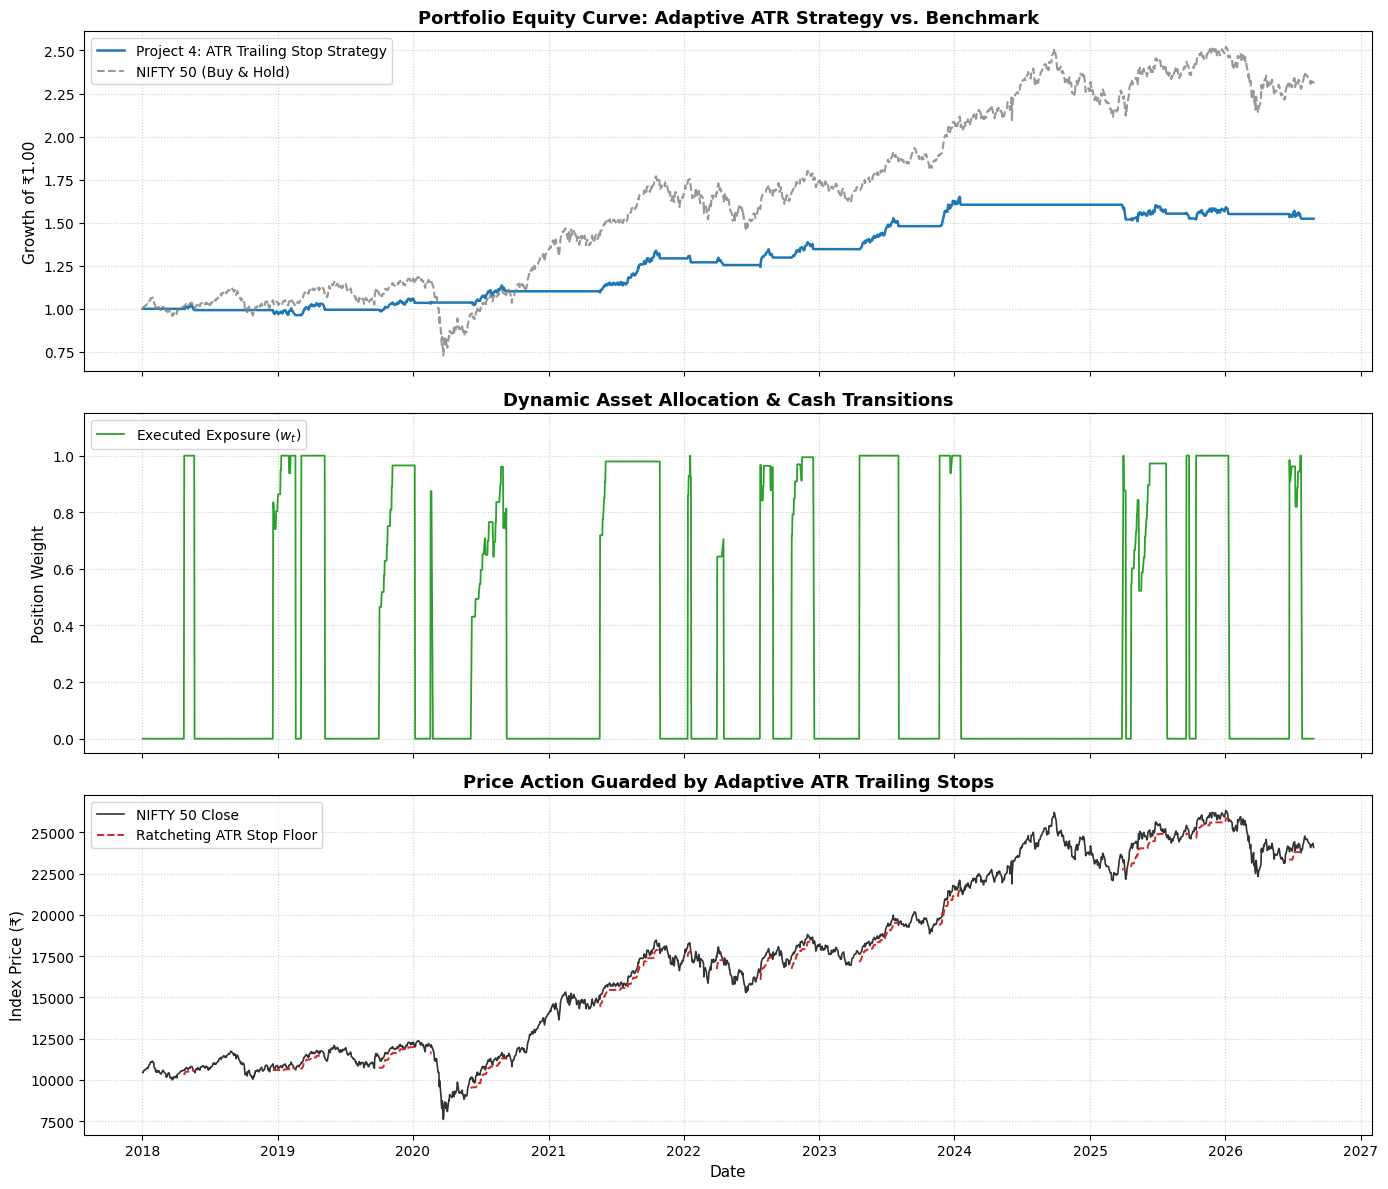

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Panel 1: Compounded Equity Curves
axes[0].plot(df.index, df['Strategy_Equity'], label='Project 4: ATR Trailing Stop Strategy', color='#1f77b4', linewidth=1.8)
axes[0].plot(df.index, df['Benchmark_Equity'], label='NIFTY 50 (Buy & Hold)', color='#7f7f7f', linestyle='--', alpha=0.8)
axes[0].set_title('Portfolio Equity Curve: Adaptive ATR Strategy vs. Benchmark', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Growth of ₹1.00', fontsize=11)
axes[0].legend(loc='upper left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Dynamic Position Exposure
axes[1].plot(df.index, df['Position'], label='Executed Exposure ($w_t$)', color='#2ca02c', linewidth=1.3)
axes[1].set_title('Dynamic Asset Allocation & Cash Transitions', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Position Weight', fontsize=11)
axes[1].set_ylim(-0.05, 1.15)
axes[1].legend(loc='upper left')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Price Action with Trailing Stop Floor
axes[2].plot(df.index, df['Close'], label='NIFTY 50 Close', color='#333333', linewidth=1.2)
axes[2].plot(df.index, df['Stop_Level'].replace(0.0, np.nan), label='Ratcheting ATR Stop Floor', color='#d62728', linestyle='--', linewidth=1.4)
axes[2].set_title('Price Action Guarded by Adaptive ATR Trailing Stops', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Index Price (₹)', fontsize=11)
axes[2].set_xlabel('Date', fontsize=11)
axes[2].legend(loc='upper left')
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('nifty50_atr_strategy_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()